<a href="https://colab.research.google.com/github/CECS-AI/ai101-assignment3-prangara-vols/blob/main/Assignment3a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import numpy as np  # Import numpy for numerical operations, especially for random data generation.
import matplotlib.pyplot as plt  # Import matplotlib.pyplot for creating static, interactive, and animated visualizations.
import seaborn as sns  # Import seaborn for statistical data visualization, built on matplotlib.
from sklearn.model_selection import train_test_split  # Import train_test_split to divide data into training and testing sets.
from sklearn.linear_model import LinearRegression  # Import LinearRegression for building the linear regression model.
from sklearn.metrics import mean_squared_error, r2_score  # Import metrics for evaluating model performance.

In [19]:
from google.colab import drive  # Import drive from google.colab to mount Google Drive.
drive.mount('/content/drive')  # Mount Google Drive to access files stored there.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import pandas as pd  # Import pandas for data manipulation and analysis, especially for DataFrames.

file_path = '/content/drive/My Drive/Colab Notebooks/Hitters.csv'  # Define the path to the CSV file. Update if your file location changes.
try:
    df = pd.read_csv(file_path)  # Attempt to read the CSV file into a pandas DataFrame.
    print("File loaded successfully!")  # Confirm successful file loading.
    display(df.head())  # Display the first few rows of the DataFrame to inspect its structure and data.
except FileNotFoundError:
    print(f"File not found at {file_path}. Please check the path and try again.")  # Handle the error if the file is not found.
except Exception as e:
    print(f"An error occurred: {e}")  # Handle any other unexpected errors during file loading.

File loaded successfully!


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


### Data Overview

Let's get a general understanding of the dataset. This includes:

1.  **`df.info()`**: Provides a concise summary of the DataFrame, including the number of entries, number of columns, column names, non-null counts, and data types.
2.  **`df.describe()`**: Generates descriptive statistics of the numerical columns in the DataFrame, such as count, mean, standard deviation, min, max, and quartiles.
3.  **`df.isnull().sum()`**: Counts the number of missing values (nulls) in each column, which is crucial for data cleaning.

In [21]:
# Display a concise summary of the DataFrame, including data types and non-null values.
display(df.info())  # Provides information about the DataFrame, including column data types and non-null counts.

# Display descriptive statistics for numerical columns.
display(df.describe())  # Generates descriptive statistics (mean, std, min, max, quartiles) for numerical columns.

# Display the count of missing values for each column.
display(df.isnull().sum())  # Shows the sum of null values for each column, highlighting missing data.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      322 non-null    int64  
 1   Hits       322 non-null    int64  
 2   HmRun      322 non-null    int64  
 3   Runs       322 non-null    int64  
 4   RBI        322 non-null    int64  
 5   Walks      322 non-null    int64  
 6   Years      322 non-null    int64  
 7   CAtBat     322 non-null    int64  
 8   CHits      322 non-null    int64  
 9   CHmRun     322 non-null    int64  
 10  CRuns      322 non-null    int64  
 11  CRBI       322 non-null    int64  
 12  CWalks     322 non-null    int64  
 13  League     322 non-null    object 
 14  Division   322 non-null    object 
 15  PutOuts    322 non-null    int64  
 16  Assists    322 non-null    int64  
 17  Errors     322 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague  322 non-null    object 
dtypes: float64

None

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
count,322.000000,322.000000,322.000000,322.000000,322.000000,322.000000,322.000000,322.00000,322.000000,322.000000,322.000000,322.000000,322.000000,322.000000,322.000000,322.000000,263.000000
mean,380.928571,101.024845,10.770186,50.909938,48.027950,38.742236,7.444099,2648.68323,717.571429,69.490683,358.795031,330.118012,260.239130,288.937888,106.913043,8.040373,535.925882
std,153.404981,46.454741,8.709037,26.024095,26.166895,21.639327,4.926087,2324.20587,654.472627,86.266061,334.105886,333.219617,267.058085,280.704614,136.854876,6.368359,451.118681
min,16.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,19.00000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67.500000
25%,255.250000,64.000000,4.000000,30.250000,28.000000,22.000000,4.000000,816.75000,209.000000,14.000000,100.250000,88.750000,67.250000,109.250000,7.000000,3.000000,190.000000
50%,379.500000,96.000000,8.000000,48.000000,44.000000,35.000000,6.000000,1928.00000,508.000000,37.500000,247.000000,220.500000,170.500000,212.000000,39.500000,6.000000,425.000000
75%,512.000000,137.000000,16.000000,69.000000,64.750000,53.000000,11.000000,3924.25000,1059.250000,90.000000,526.250000,426.250000,339.250000,325.000000,166.000000,11.000000,750.000000
max,687.000000,238.000000,40.000000,130.000000,121.000000,105.000000,24.000000,14053.00000,4256.000000,548.000000,2165.000000,1659.000000,1566.000000,1378.000000,492.000000,32.000000,2460.000000


,0
AtBat,0
Hits,0
HmRun,0
Runs,0
RBI,0
Walks,0
Years,0
CAtBat,0
CHits,0
CHmRun,0


### Handling Missing Values

Based on the `df.isnull().sum()` output, the 'Salary' column contains missing values. These rows need to be removed to ensure the integrity of our dataset for analysis and model training.

In [22]:
# Remove rows with any missing values. This primarily addresses the 'Salary' column's missing entries.
df_cleaned = df.dropna()  # Creates a new DataFrame `df_cleaned` by dropping rows containing any NaN values.

# Display the shape of the DataFrame after dropping nulls to confirm the change in row count.
print(f"Shape of DataFrame after dropping nulls: {df_cleaned.shape}")  # Prints the new dimensions (rows, columns) of the DataFrame.

# Verify that there are no more missing values in the cleaned DataFrame.
display(df_cleaned.isnull().sum())  # Confirms that all missing values have been handled by showing zero nulls per column.

Shape of DataFrame after dropping nulls: (263, 20)


,0
AtBat,0
Hits,0
HmRun,0
Runs,0
RBI,0
Walks,0
Years,0
CAtBat,0
CHits,0
CHmRun,0


### Visualize Relationships: Scatter Plot (Hits vs. Salary)

To understand potential relationships between player performance and salary, a scatter plot of 'Hits' against 'Salary' is generated. This visualization helps to identify if there's a visible correlation or pattern between these two key variables.

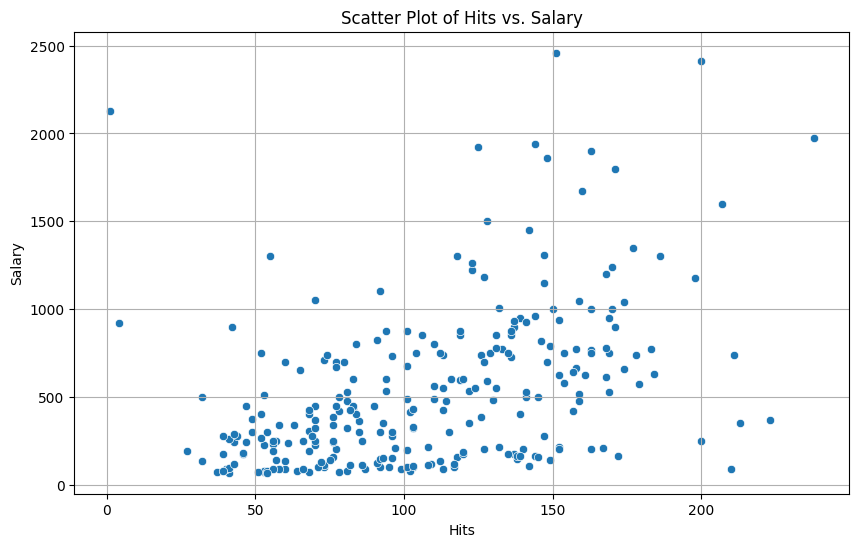

In [23]:
# Create a scatter plot of 'Hits' vs. 'Salary' to visualize their relationship.
plt.figure(figsize=(10, 6))  # Sets the size of the plot for better visual clarity.
sns.scatterplot(x='Hits', y='Salary', data=df_cleaned)  # Generates a scatter plot using Seaborn, with 'Hits' on the x-axis and 'Salary' on the y-axis.
plt.title('Scatter Plot of Hits vs. Salary')  # Adds a descriptive title to the plot.
plt.xlabel('Hits')  # Labels the x-axis.
plt.ylabel('Salary')  # Labels the y-axis.
plt.grid(True)  # Adds a grid to the plot for easier reading of values.
plt.show()  # Displays the generated scatter plot.

### Visualize Relationships Between All Columns: Correlation Matrix Heatmap

To comprehensively understand the interplay between all numerical variables and identify potential multicollinearity or strong predictors, a correlation matrix heatmap is generated. This visual representation highlights the Pearson correlation coefficients between each pair of variables, with colors indicating the strength and direction of the correlation.

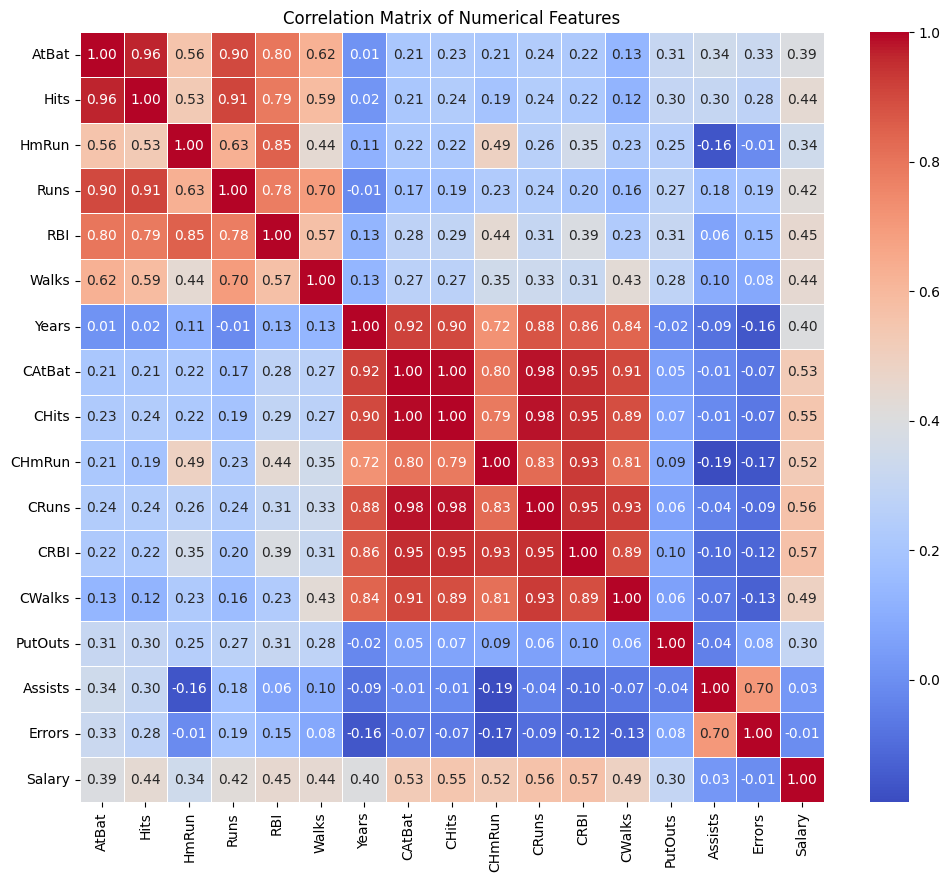

In [24]:
# Calculate the correlation matrix for numerical columns.
correlation_matrix = df_cleaned.select_dtypes(include=['int64', 'float64']).corr()  # Computes the pairwise correlation between numerical columns.

# Set up the matplotlib figure for the heatmap.
plt.figure(figsize=(12, 10))  # Defines the size of the plot for better visualization of the heatmap.

# Create a heatmap of the correlation matrix.
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)  # Generates a heatmap.
# `annot=True` displays the correlation values on the heatmap.
# `cmap='coolwarm'` sets the color scheme.
# `fmt='.2f'` formats the annotations to two decimal places.
# `linewidths=.5` adds lines between cells.
plt.title('Correlation Matrix of Numerical Features')  # Adds a title to the heatmap.
plt.show()  # Displays the generated heatmap.

### Data Preprocessing for Machine Learning

Before building a machine learning model, it's essential to preprocess the data. This involves:

1.  **Defining Target and Features**: Identifying the dependent variable (target) and independent variables (features).
2.  **Handling Categorical Features**: Converting categorical variables into a numerical format that machine learning algorithms can understand. One-hot encoding is a common technique for this.

In [25]:
# Define target variable (y) and features (X).
# 'Salary' is the target variable we want to predict.
y = df_cleaned['Salary']  # Assigns the 'Salary' column as the target variable.
X = df_cleaned.drop('Salary', axis=1)  # Assigns all other columns as features, dropping 'Salary' from X.

# Identify categorical and numerical features.
categorical_features = X.select_dtypes(include=['object']).columns  # Selects columns with 'object' dtype (strings) as categorical.
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns  # Selects columns with 'int64' or 'float64' dtypes as numerical.

print(f"Categorical Features: {list(categorical_features)}")  # Prints the list of identified categorical features.
print(f"Numerical Features: {list(numerical_features)}")  # Prints the list of identified numerical features.

# Perform one-hot encoding for categorical features.
# drop_first=True avoids multicollinearity by dropping the first category of each feature.
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)  # Converts categorical variables into dummy/indicator variables.

# Display the first few rows of the encoded features and their shape.
print("\nShape of features after one-hot encoding:", X_encoded.shape)  # Prints the new shape of the feature DataFrame after encoding.
display(X_encoded.head())  # Displays the first few rows of the one-hot encoded DataFrame.

Categorical Features: ['League', 'Division', 'NewLeague']
Numerical Features: ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'PutOuts', 'Assists', 'Errors']

Shape of features after one-hot encoding: (263, 19)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,League_N,Division_W,NewLeague_N
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,632,43,10,True,True,True
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,880,82,14,False,True,False
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,200,11,3,True,False,True
4,321,87,10,39,42,30,2,396,101,12,48,46,33,805,40,4,True,False,True
5,594,169,4,74,51,35,11,4408,1133,19,501,336,194,282,421,25,False,True,False


### Split Data into Training and Testing Sets

To evaluate the performance of our machine learning model, the dataset is divided into training and testing sets. The training set is used to train the model, while the testing set is used to assess its generalization capabilities on unseen data.

In [26]:
# Split the data into training and testing sets.
# A common split is 80% for training and 20% for testing.
# random_state ensures reproducibility of the split.
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)  # Splits features (X) and target (y) into training and testing sets.
# `test_size=0.2` allocates 20% of the data for testing, 80% for training.
# `random_state=42` ensures the split is consistent across multiple runs.

print(f"Shape of X_train: {X_train.shape}")  # Prints the shape of the training features.
print(f"Shape of X_test: {X_test.shape}")  # Prints the shape of the testing features.
print(f"Shape of y_train: {y_train.shape}")  # Prints the shape of the training target variable.
print(f"Shape of y_test: {y_test.shape}")  # Prints the shape of the testing target variable.

Shape of X_train: (210, 19)
Shape of X_test: (53, 19)
Shape of y_train: (210,)
Shape of y_test: (53,)


### Build a Machine Learning Model: Linear Regression

With the data preprocessed and split, a Linear Regression model is now built. This model will learn the relationship between the features (player statistics) and the target variable (Salary) from the training data.

In [27]:
# Initialize the Linear Regression model.
model = LinearRegression()  # Creates an instance of the Linear Regression model.

# Train the model using the training data.
model.fit(X_train, y_train)  # Trains the model using the training features (X_train) and training target (y_train).

print("Linear Regression model trained successfully.")  # Confirms that the model training is complete.
print(f"Model coefficients: {model.coef_}")  # Prints the learned coefficients for each feature in the model.
print(f"Model intercept: {model.intercept_}")  # Prints the intercept (bias) of the linear regression model.

Linear Regression model trained successfully.
Model coefficients: [-1.47860426e+00  7.42224568e+00  4.78627278e+00 -2.85431685e+00
 -1.44287843e+00  5.55339665e+00  8.05732218e+00 -2.30339791e-01
  1.09071605e-01 -4.69950384e-01  1.68726644e+00  9.41593552e-01
 -8.20583434e-01  2.47927436e-01  2.25917923e-01 -6.50872283e-01
  1.07961033e+02 -1.13843871e+02 -6.37509007e+01]
Model intercept: 16.383751178341754


### Generate Test Data for Prediction

To evaluate the model's predictive capability on new, unseen data, 100 random data points are generated. It's crucial that these synthetic data points maintain a similar order of magnitude and distribution to the original features to ensure realistic predictions. This helps simulate real-world scenarios without needing additional actual data.

In [28]:
# Generate 100 random data points for testing the model.
# Ensure the random data for each column is within the same order of magnitude as the original data.
random_data = pd.DataFrame({  # Creates a new DataFrame for random data.
    col: np.random.uniform(X_encoded[col].min(), X_encoded[col].max(), 100)  # Generates 100 random numbers for each column.
    # The numbers are uniformly distributed between the minimum and maximum values of the original encoded features.
    for col in X_encoded.columns  # Iterates through each column of the one-hot encoded features.
})

print("Generated 100 random data points for prediction.")  # Confirms the generation of random data.
display(random_data.head())  # Displays the first few rows of the generated random data to verify its structure.

Generated 100 random data points for prediction.


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,League_N,Division_W,NewLeague_N
0,191.386868,50.229866,32.286483,85.006663,55.692471,57.808663,10.656035,295.170698,4114.301186,299.268810,127.859772,1132.217616,247.614764,718.706353,145.960813,29.287562,0.275167,0.828806,0.773599
1,199.763446,165.111545,12.933468,26.593592,50.438025,3.532971,8.176926,9158.227370,1652.800974,215.888630,963.383385,1559.008452,1472.323121,1147.656315,164.761451,21.934658,0.491452,0.848927,0.707567
2,587.434489,179.552854,39.381645,116.217206,110.005306,56.071257,6.640036,2409.617783,2819.241027,368.021748,258.230291,909.108249,804.380256,983.197400,32.367420,29.940964,0.347344,0.465039,0.671382
3,554.361337,105.583847,35.228689,125.279808,29.085643,15.272594,20.495550,49.779893,2546.118431,135.401170,1307.927368,382.774766,1565.329871,630.540450,23.311497,14.193099,0.370916,0.759053,0.934365
4,263.288726,131.860813,39.944767,35.700221,50.700846,30.478956,10.439398,12773.387091,85.066302,36.174822,733.053259,1516.343096,406.258911,972.498577,109.681347,15.578670,0.651814,0.831275,0.997655


### Predict Salaries for the Generated Test Data

With the random data generated, the trained Linear Regression model is used to predict 'Salary' values for these new data points. This step demonstrates how the model would perform on unseen data that resembles the original dataset.

In [29]:
# Use the trained model to make predictions on the generated random data.
predictions = model.predict(random_data)  # Generates salary predictions using the trained model on the `random_data`.

# Replace any negative predicted salaries with 0, as salaries cannot be negative.
predictions[predictions < 0] = 0  # Sets any predicted salary values less than 0 to 0, ensuring non-negative salaries.

print("Predictions for the generated random data (negative values capped at 0):")  # Informative message about the displayed predictions.
display(pd.DataFrame(predictions, columns=['Predicted Salary']).head())  # Displays the first few capped predicted salaries in a DataFrame.

Predictions for the generated random data (negative values capped at 0):


,Predicted Salary
0,1741.539791
1,1018.607073
2,927.930874
3,1531.173539
4,424.500454


### Original Predicted Salaries (including negative values)

This cell shows the raw predictions from the Linear Regression model before any post-processing (like capping negative values at zero) was applied. This helps to see the values that the model originally generated.

In [30]:
# Use the trained model to make predictions on the generated random data, without capping.
original_predictions = model.predict(random_data)  # Generates raw salary predictions from the trained model without any modification.

print("Original predictions for the generated random data (including negatives):")  # Informative message about the displayed predictions.
display(pd.DataFrame(original_predictions, columns=['Original Predicted Salary']).head())  # Displays the first few raw predicted salaries, including potential negative values.

Original predictions for the generated random data (including negatives):


,Original Predicted Salary
0,1741.539791
1,1018.607073
2,927.930874
3,1531.173539
4,424.500454


### Visualize Predicted Salaries Distribution

To better understand the range and distribution of the salaries predicted by our model for the random data, we will create a histogram. This visualization helps to see the frequency of different salary ranges within our predictions.

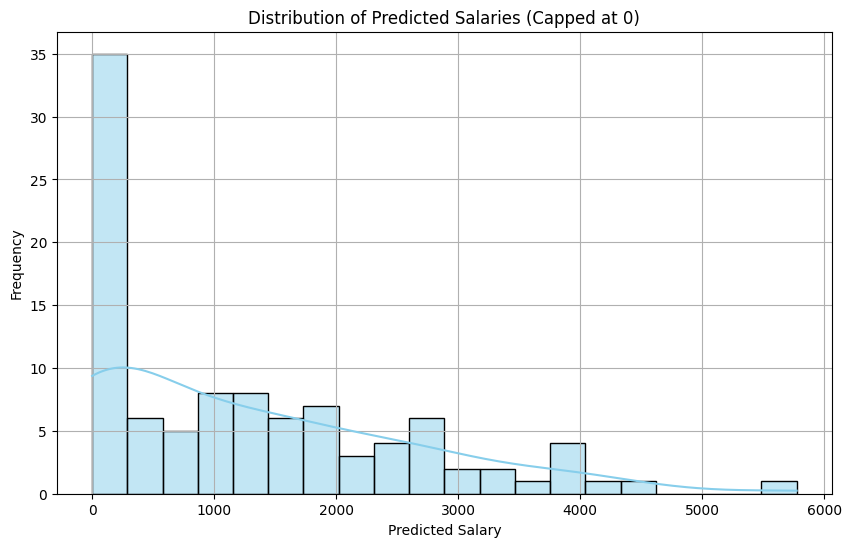

In [31]:
# Visualize the distribution of the predicted salaries
plt.figure(figsize=(10, 6))  # Sets the figure size for better readability of the plot.
sns.histplot(predictions, bins=20, kde=True, color='skyblue')  # Creates a histogram of the `predictions` data.
# `bins=20` specifies 20 bins for the histogram.
# `kde=True` overlays a Kernel Density Estimate plot.
# `color='skyblue'` sets the color of the bars.
plt.title('Distribution of Predicted Salaries (Capped at 0)')  # Adds a descriptive title to the plot.
plt.xlabel('Predicted Salary')  # Labels the x-axis as 'Predicted Salary'.
plt.ylabel('Frequency')  # Labels the y-axis as 'Frequency'.
plt.grid(True)  # Adds a grid to the plot for easier data interpretation.
plt.show()  # Displays the generated histogram.

### Compare Predicted vs. Original Salary Distributions

To assess how well our model's predictions align with the actual salary data, we will compare the distribution of the capped predicted salaries (from the random data) against the distribution of the original 'Salary' values from our cleaned dataset. This comparison helps in understanding if the model is generating plausible salary ranges.

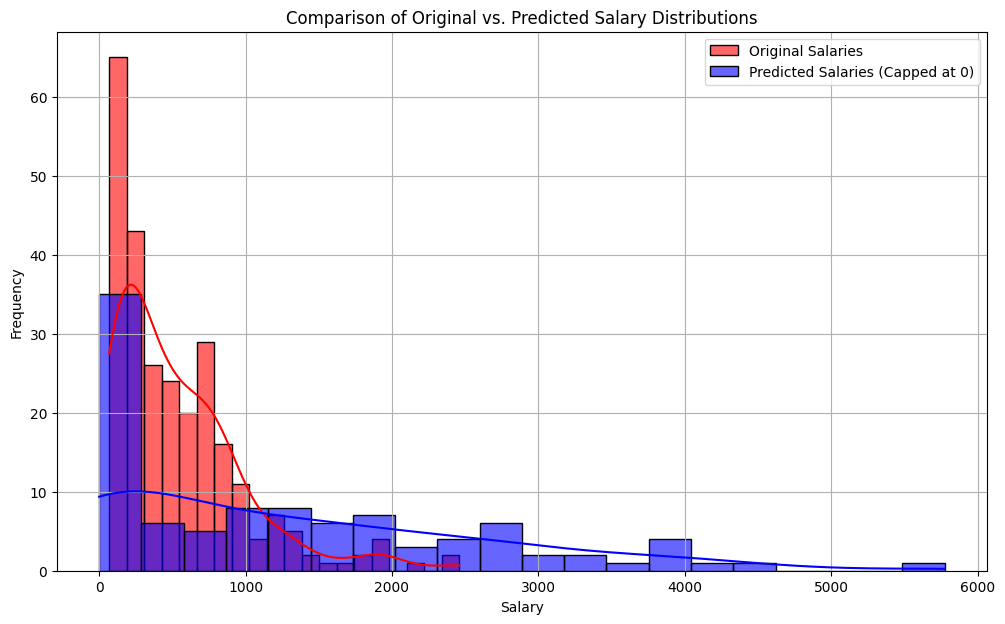

In [32]:
# Compare the distribution of predicted salaries with the original salary distribution
plt.figure(figsize=(12, 7))  # Sets the figure size for better readability of the comparison plot.
# Plot histogram for original salaries.
sns.histplot(df_cleaned['Salary'], bins=20, kde=True, color='red', label='Original Salaries', alpha=0.6)  # Creates a histogram for the actual 'Salary' values.
# `alpha=0.6` makes the bars semi-transparent for overlaying.
# Plot histogram for predicted salaries (capped at 0).
sns.histplot(predictions, bins=20, kde=True, color='blue', label='Predicted Salaries (Capped at 0)', alpha=0.6)  # Creates a histogram for the capped predicted salaries.
plt.title('Comparison of Original vs. Predicted Salary Distributions')  # Adds a descriptive title to the comparison plot.
plt.xlabel('Salary')  # Labels the x-axis as 'Salary'.
plt.ylabel('Frequency')  # Labels the y-axis as 'Frequency'.
plt.legend()  # Displays the legend to differentiate between 'Original Salaries' and 'Predicted Salaries'.
plt.grid(True)  # Adds a grid to the plot for easier data interpretation.
plt.show()  # Displays the generated comparison histogram.